# 01. 데이터 수집 — Steam 한국어 리뷰

**목표:** Steam 공개 리뷰 엔드포인트에서 장르가 다양한 게임 16종의 **한국어 리뷰**를 게임당 최대 1,000건 수집한다.

| 항목 | 내용 |
|---|---|
| 출처 | Steam Store 공개 리뷰 엔드포인트 `https://store.steampowered.com/ajaxappreviews/{appid}?json=1` (API 키 불필요) |
| 언어 | `language=koreana` |
| 정렬 | ① 도움됨 순(`filter=all`, 최근 365일) → 부족하면 ② 최신순(`filter=recent`)으로 보충 |
| 라이선스 | Steam 이용약관(Steam Subscriber Agreement)에 따른 공개 데이터, 비상업적 학술 목적 사용. 원문 재배포 최소화 |
| 개인정보 | 작성자 `steamid`·닉네임·프로필 URL·아바타는 **저장하지 않음** (플레이타임 등 수치만 보존) |

> 참고: 기존 문서에 나오는 `/appreviews/{appid}` 경로는 2026-11 기준 Steam 홈으로 302 리다이렉트되어 JSON을 받을 수 없다. 같은 형식의 JSON을 반환하는 `/ajaxappreviews/` 경로를 사용한다.

**산출물**
- `data/raw/reviews/{appid}.jsonl` — 게임별 원본(체크포인트, 끊겨도 이어받기)
- `data/raw/steam_reviews_ko_raw.csv` — 통합 원본 테이블
- `figures/01_*.png` — 수집 현황 그래프

In [1]:
# ── 환경 설정 ────────────────────────────────────────────
import os, sys, json, time, random
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# ▶ 본인 Google Drive의 프로젝트 폴더 경로로 수정
def find_root():
    # 프로젝트 폴더 자동 탐색. Drive의 한글 폴더명이 NFD(자모 분리)로 저장되면
    # "ML 기말" 같은 문자열 경로가 일치하지 않으므로, MyDrive를 직접 훑어
    # data/processed/reviews_clean.csv가 있는 폴더를 찾는다(검수 파일이 있는 쪽 우선).
    if os.environ.get("ML_ROOT"):
        return Path(os.environ["ML_ROOT"])
    base = Path("/content/drive/MyDrive")
    cands = [p for p in [base, *base.glob("*"), *base.glob("*/*")]
             if p.is_dir() and (p / "data" / "processed" / "reviews_clean.csv").exists()]
    if not cands:
        print("⚠ 프로젝트 폴더를 찾지 못해 기본 경로를 사용합니다.")
        return base / "ML 기말"
    cands.sort(key=lambda p: not (p / "data" / "labeling" / "test_verify.csv").exists())
    if len(cands) > 1:
        print("⚠ 프로젝트 폴더 후보가 여러 개입니다 → 첫 번째 사용:", *cands, sep="\n   ")
    return cands[0]

ROOT = find_root()

RAW_DIR = ROOT / "data" / "raw" / "reviews"
FIG_DIR = ROOT / "figures"
RAW_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT)

Mounted at /content/drive
ROOT: /content/drive/MyDrive/머신러닝 포트폴리오


In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("requests", requests.__version__, "| pandas", pd.__version__)

requests 2.32.4 | pandas 2.2.3


## 1. 수집 대상 게임

속성(그래픽·최적화·스토리·게임플레이·조작·사운드·가격·버그)이 고르게 언급되도록 **장르를 섞어** 선정했다.
- 최적화·버그 논란작: Cyberpunk 2077, Monster Hunter Wilds, Palworld
- 스토리 중심: Red Dead Redemption 2, The Witcher 3, Baldur's Gate 3
- 조작·전투 중심: ELDEN RING, Black Myth: Wukong, Hades, CS2
- 사운드·분위기, 가격 대비 가치: Stardew Valley, Terraria, Lethal Company

In [3]:
GAMES = [
    # appid,   이름,                      장르
    (578080,  "PUBG: BATTLEGROUNDS",      "Battle Royale"),
    (730,     "Counter-Strike 2",         "FPS"),
    (1172470, "Apex Legends",             "Battle Royale"),
    (271590,  "Grand Theft Auto V",       "Open World Action"),
    (1174180, "Red Dead Redemption 2",    "Open World Action"),
    (1091500, "Cyberpunk 2077",           "Open World RPG"),
    (1245620, "ELDEN RING",               "Soulslike"),
    (2358720, "Black Myth: Wukong",       "Action"),
    (2246340, "Monster Hunter Wilds",     "Action"),
    (1086940, "Baldur's Gate 3",          "CRPG"),
    (292030,  "The Witcher 3",            "RPG"),
    (413150,  "Stardew Valley",           "Simulation"),
    (105600,  "Terraria",                 "Sandbox"),
    (1623730, "Palworld",                 "Survival"),
    (1966720, "Lethal Company",           "Co-op Horror"),
    (1145360, "Hades",                    "Roguelike"),
]

PER_GAME   = int(os.environ.get("PER_GAME", 1000))  # 게임당 목표 리뷰 수
FORCE_RECOLLECT = False   # True면 기존 파일을 무시하고 새로 수집 (라벨과 어긋나므로 주의)
SLEEP_SEC  = 1.0      # 요청 간격(초) — 서버 부담 최소화
MAX_RETRY  = 5
ENDPOINT   = "https://store.steampowered.com/ajaxappreviews/{appid}"
print(f"{len(GAMES)}개 게임 × 최대 {PER_GAME}건 = 최대 {len(GAMES)*PER_GAME:,}건")

16개 게임 × 최대 1000건 = 최대 16,000건


## 2. 수집 함수

- `cursor` 기반 페이지네이션 (한 번에 최대 100건)
- JSON이 아닌 응답·429·네트워크 오류는 지수 백오프로 재시도
- 같은 cursor가 반복되거나 새 리뷰가 없으면 종료
- 게임별 JSONL에 저장하고, 이미 목표치를 채운 게임은 건너뜀 → Colab 연결이 끊겨도 다시 실행하면 이어서 진행

In [4]:
session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0 (academic-project review collector)"})

def get_page(appid, cursor, filter_):
    params = {
        "json": 1, "language": "koreana", "filter": filter_,
        "review_type": "all", "purchase_type": "all",
        "num_per_page": 100, "cursor": cursor,
    }
    if filter_ == "all":
        params["day_range"] = 365          # 도움됨 순은 최대 365일까지만 지원
    for attempt in range(MAX_RETRY):
        try:
            r = session.get(ENDPOINT.format(appid=appid), params=params, timeout=30)
            if r.status_code == 429:
                raise RuntimeError("429 Too Many Requests")
            data = r.json()
            if data.get("success") != 1:
                raise RuntimeError(f"success={data.get('success')}")
            return data
        except Exception as e:
            wait = 2 ** attempt + random.random()
            print(f"    [재시도 {attempt+1}/{MAX_RETRY}] {appid} {filter_}: {e} → {wait:.1f}s 대기")
            time.sleep(wait)
    return None

def slim(review, appid):
    """개인정보(steamid, 닉네임, 프로필)를 제거하고 필요한 필드만 남긴다."""
    a = review.get("author", {})
    return {
        "recommendationid": review["recommendationid"],
        "appid": appid,
        "language": review.get("language"),
        "review": review.get("review", ""),
        "voted_up": review.get("voted_up"),
        "votes_up": review.get("votes_up"),
        "votes_funny": review.get("votes_funny"),
        "weighted_vote_score": float(review.get("weighted_vote_score", 0) or 0),
        "comment_count": review.get("comment_count"),
        "steam_purchase": review.get("steam_purchase"),
        "received_for_free": review.get("received_for_free"),
        "written_during_early_access": review.get("written_during_early_access"),
        "timestamp_created": review.get("timestamp_created"),
        "playtime_forever": a.get("playtime_forever"),
        "playtime_at_review": a.get("playtime_at_review"),
        "num_games_owned": a.get("num_games_owned"),
        "num_reviews": a.get("num_reviews"),
    }

def collect_game(appid, target):
    path = RAW_DIR / f"{appid}.jsonl"
    if path.exists() and not FORCE_RECOLLECT:
        # 이미 수집한 게임은 건수와 상관없이 건너뜀 — 다시 모으면 그사이 달린 새 리뷰가 섞여
        # 정제 데이터와 라벨(to_label.csv)이 어긋난다 (재현성 유지)
        n = sum(1 for _ in open(path, encoding="utf-8"))
        print(f"  · 이미 {n}건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)")
        return n
    rows, seen = [], set()
    for filter_ in ["all", "recent"]:          # 도움됨 순 → 최신순 보충
        cursor, prev_cursor = "*", None
        while len(rows) < target:
            data = get_page(appid, cursor, filter_)
            if data is None:
                break
            new = [slim(r, appid) for r in data.get("reviews", [])
                   if r["recommendationid"] not in seen]
            for r in new:
                seen.add(r["recommendationid"])
            rows.extend(new)
            prev_cursor, cursor = cursor, data.get("cursor")
            time.sleep(SLEEP_SEC)
            if not new or not cursor or cursor == prev_cursor:
                break
        print(f"  · filter={filter_:<6} 누적 {len(rows)}건")
        if len(rows) >= target:
            break
    rows = rows[:target]
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    return len(rows)

## 3. 수집 실행 (약 5~10분)

In [5]:
t0 = time.time()
summary = []
for i, (appid, name, genre) in enumerate(GAMES, 1):
    print(f"[{i:2d}/{len(GAMES)}] {name} ({appid})")
    n = collect_game(appid, PER_GAME)
    summary.append((name, n))
print(f"\n완료: 총 {sum(n for _, n in summary):,}건, {time.time()-t0:.0f}초")

[ 1/16] PUBG: BATTLEGROUNDS (578080)
  · 이미 1000건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)
[ 2/16] Counter-Strike 2 (730)
  · 이미 1000건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)
[ 3/16] Apex Legends (1172470)
  · 이미 789건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)
[ 4/16] Grand Theft Auto V (271590)
  · 이미 1000건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)
[ 5/16] Red Dead Redemption 2 (1174180)
  · 이미 1000건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)
[ 6/16] Cyberpunk 2077 (1091500)
  · 이미 1000건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)
[ 7/16] ELDEN RING (1245620)
  · 이미 1000건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)
[ 8/16] Black Myth: Wukong (2358720)
  · 이미 843건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)
[ 9/16] Monster Hunter Wilds (2246340)
  · 이미 1000건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)
[10/16] Baldur's Gate 3 (1086940)
  · 이미 1000건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)
[11/16] The Witcher 3 (292030)
  · 이미 1000건 수집됨 → 건너뜀 (재수집하려면 FORCE_RECOLLECT=True)
[12/16] Stardew Valley (413150)
  · 이미 10

## 4. 통합 테이블 생성 및 저장

In [6]:
meta = pd.DataFrame(GAMES, columns=["appid", "game", "genre"])
frames = []
for appid, *_ in GAMES:
    p = RAW_DIR / f"{appid}.jsonl"
    if p.exists():
        frames.append(pd.read_json(p, lines=True, dtype={"recommendationid": str}))
df = pd.concat(frames, ignore_index=True).merge(meta, on="appid", how="left")
df["created"] = pd.to_datetime(df["timestamp_created"], unit="s")
df["len_chars"] = df["review"].str.len()

before = len(df)
df = df.drop_duplicates("recommendationid").reset_index(drop=True)
print(f"전체 {before:,}건 → recommendationid 중복 제거 후 {len(df):,}건")

OUT_CSV = ROOT / "data" / "raw" / "steam_reviews_ko_raw.csv"
df.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")
print("저장:", OUT_CSV)
df.head()

전체 14,909건 → recommendationid 중복 제거 후 14,909건
저장: /content/drive/MyDrive/머신러닝 포트폴리오/data/raw/steam_reviews_ko_raw.csv


,recommendationid,appid,language,review,voted_up,votes_up,votes_funny,weighted_vote_score,comment_count,steam_purchase,...,written_during_early_access,timestamp_created,playtime_forever,playtime_at_review,num_games_owned,num_reviews,game,genre,created,len_chars
0,235528743,578080,koreana,이벤트전 자국 스트리머가 방플당해도 그냥 넘어갑시다~\n그 국가 공계는 조롱 ㅋㅋ ...,False,2127,120,0.966256,0,True,...,False,2026-09-18 12:10:36,3271,3271,0,2,PUBG: BATTLEGROUNDS,Battle Royale,2026-09-18 12:10:36,58
1,233826782,578080,koreana,어떤 ㅈ같은 짱깨련이 계정 해킹하고 핵썼나 갑자기 중국에서 로그인 됬다길래 비번 변...,False,447,16,0.942136,2,True,...,False,2026-08-27 14:54:30,15576,15576,45,1,PUBG: BATTLEGROUNDS,Battle Royale,2026-08-27 14:54:30,114
2,209623282,578080,koreana,배그 특유의 이중가차 시스템은 가정교육이 덜 되있다고 감히 판단할 수 있다. 어느 ...,False,66,6,0.840239,2,True,...,False,2025-11-19 14:00:57,49622,34327,25,3,PUBG: BATTLEGROUNDS,Battle Royale,2025-11-19 14:00:57,79
3,232310352,578080,koreana,"처음 나왔을 때가 고딩이였네요. 용돈 모아서 유료게임 처음으로 사보고, 친구들과 즐...",True,33,10,0.779705,0,True,...,False,2026-08-08 01:01:03,22723,18932,3,1,PUBG: BATTLEGROUNDS,Battle Royale,2026-08-08 01:01:03,88
4,224959057,578080,koreana,매력적이고 잘 만든 게임은 맞지만 운영을 진짜 못한다\n출시된 지 9년이나 됐는데 ...,True,41,4,0.757689,0,True,...,False,2026-05-07 12:58:09,65933,59661,0,1,PUBG: BATTLEGROUNDS,Battle Royale,2026-05-07 12:58:09,805


## 5. 수집 현황 요약

In [7]:
by_game = (df.groupby(["game", "genre"])
             .agg(reviews=("review", "size"),
                  recommend_rate=("voted_up", "mean"),
                  median_chars=("len_chars", "median"),
                  median_playtime_h=("playtime_at_review", lambda s: s.median() / 60),
                  oldest=("created", "min"),
                  newest=("created", "max"))
             .sort_values("reviews", ascending=False)
             .round(2))
print(f"총 {len(df):,}건 / 게임 {df['game'].nunique()}종 / 추천 비율 {df['voted_up'].mean():.1%}")
print(f"리뷰 길이(글자) — 중앙값 {df['len_chars'].median():.0f}, 평균 {df['len_chars'].mean():.0f}, 최대 {df['len_chars'].max():,}")
by_game

총 14,909건 / 게임 16종 / 추천 비율 84.8%
리뷰 길이(글자) — 중앙값 41, 평균 95, 최대 7,956


,,reviews,recommend_rate,median_chars,median_playtime_h,oldest,newest
game,genre,,,,,,
Baldur's Gate 3,CRPG,1000,0.93,52.0,126.23,2025-11-19 09:12:55,2026-11-18 20:09:17
Counter-Strike 2,FPS,1000,0.76,19.0,90.26,2025-11-19 06:05:56,2026-11-19 03:45:20
ELDEN RING,Soulslike,1000,0.90,41.0,100.65,2025-11-19 07:53:11,2026-11-18 15:22:13
Cyberpunk 2077,Open World RPG,1000,0.90,79.0,69.76,2025-11-20 00:43:33,2026-11-18 20:31:18
Grand Theft Auto V,Open World Action,1000,0.94,11.0,94.48,2025-11-20 06:16:31,2026-11-19 09:07:12
Palworld,Survival,1000,0.92,64.0,96.23,2025-11-19 12:43:03,2026-11-19 07:46:58
PUBG: BATTLEGROUNDS,Battle Royale,1000,0.61,56.0,236.40,2025-11-19 06:49:48,2026-09-18 18:54:03
Monster Hunter Wilds,Action,1000,0.56,79.5,96.24,2025-11-19 04:35:53,2026-11-19 02:09:20
Terraria,Sandbox,1000,0.95,16.0,105.94,2025-11-19 01:05:42,2026-11-19 08:07:33


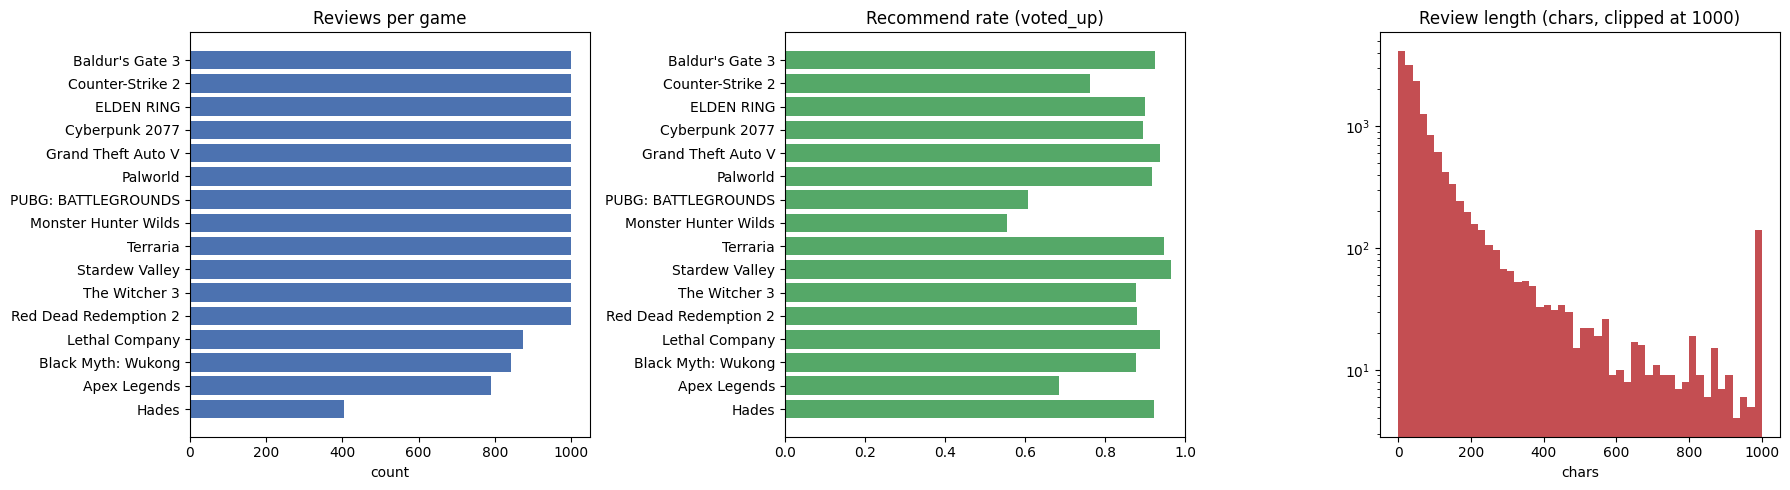

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

order = by_game.index.get_level_values("game")
counts = df["game"].value_counts().reindex(order)
axes[0].barh(counts.index[::-1], counts.values[::-1], color="#4C72B0")
axes[0].set_title("Reviews per game")
axes[0].set_xlabel("count")

rate = df.groupby("game")["voted_up"].mean().reindex(order)
axes[1].barh(rate.index[::-1], rate.values[::-1], color="#55A868")
axes[1].set_xlim(0, 1)
axes[1].set_title("Recommend rate (voted_up)")

clip = df["len_chars"].clip(upper=1000)
axes[2].hist(clip, bins=50, color="#C44E52")
axes[2].set_yscale("log")
axes[2].set_title("Review length (chars, clipped at 1000)")
axes[2].set_xlabel("chars")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_collection_overview.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# 길이 구간별 분포 — 02 전처리에서 길이 필터 기준을 정하는 근거
bins = [0, 5, 10, 20, 50, 100, 300, 1000, 10**6]
labels = ["<5", "5-9", "10-19", "20-49", "50-99", "100-299", "300-999", "1000+"]
dist = pd.cut(df["len_chars"], bins=bins, labels=labels, right=False).value_counts().reindex(labels)
pd.DataFrame({"count": dist, "ratio": (dist / len(df)).round(3)})

,count,ratio
len_chars,,
<5,1125,0.075
5-9,1181,0.079
10-19,1842,0.124
20-49,4454,0.299
50-99,3116,0.209
100-299,2372,0.159
300-999,686,0.046
1000+,133,0.009


In [10]:
# 무작위 샘플 확인
for _, r in df.sample(5, random_state=42).iterrows():
    print(f"[{r['game']}] {'👍' if r['voted_up'] else '👎'} ({r['len_chars']}자)")
    print("  ", r["review"][:200].replace("\n", " "))
    print()

[Baldur's Gate 3] 👍 (117자)
 의도치 않게 현실에서 못 해본 문어와의 사랑도,,, 크흠

[Lethal Company] 👍 (2자)
   존잼

[ELDEN RING] 👍 (16자)
   공량을 보든 안보든 재미있음!

[Palworld] 👍 (85자)
   아무리 재밌어도 1회차까지만 재밌는 게임들이 대다수인데 이 게임은 스스로에게 제약을 걸고 난이도를 변경하면서 하다 보면 계속 새로운 재미를 느낄 수 있다

[Apex Legends] 👍 (3자)
   재밌다



## 정리

- 수집 결과(건수·추천 비율·길이 분포)는 README `## 2. 데이터`에 그대로 사용한다.
- 다음 단계: `02_preprocess.ipynb` — HTML/BBCode 제거, 한국어 비율 필터, 반복 문자 정규화, 길이 필터, 중복 제거